# PS-12 : Agricultural Yield Prediction and Productivity Factor Analysis
**Data:** FAOSTAT crops (QCL) &nbsp;|&nbsp; **Target:** crop yield in **kg/ha** (model is trained on `log1p(yield)`, all metrics are reported back in kg/ha)  
**Models:** Linear / Polynomial Regression, Ridge, Lasso, Random Forest &nbsp;|&nbsp; **Tuning:** GridSearchCV &nbsp;|&nbsp; **Imbalance:** SMOTE for regression  
Unzip the dataset and put `Production_Crops_Livestock_E_All_Data_NOFLAG.csv` next to this notebook.

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import gc
import joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# ============================================================
# 2. SETTINGS
# ============================================================

SPLIT_TYPE = "random"     # "random" -> train_test_split(0.20, random_state=43)
                          # "time"   -> train on years <= 2015, test on 2016-2024
USE_REGIONAL_SHOCK = True # weather proxy (see section 11), set False to switch it off

TUNE_ROWS = 30000         # GridSearch runs on this many training rows (faster)
FIT_ROWS  = 120000        # final fit of each best model uses this many rows (None = all)
RANDOM_STATE = 43

In [3]:
# ============================================================
# 3. LOAD DATASET
# ============================================================

df = pd.read_csv("Production_Crops_Livestock_E_All_Data_NOFLAG.csv")

print("Original Dataset Shape:", df.shape)

df.head()

Original Dataset Shape: (78974, 73)


,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Y1961,...,Y2015,Y2016,Y2017,Y2018,Y2019,Y2020,Y2021,Y2022,Y2023,Y2024
0,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5312,Area harvested,ha,0.0,...,14676.0,19481.0,19793.0,20053.0,29203.0,22134.0,36862.0,36462.0,37000.0,39794.00
1,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5412,Yield,kg/ha,NaN,...,1652.1,1685.9,1378.8,1716.1,1308.3,1775.9,1743.2,1742.0,1810.8,1741.90
2,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5510,Production,t,0.0,...,24246.0,32843.0,27291.0,34413.0,38205.0,39307.0,64256.0,63515.0,67000.0,69315.64
3,2,'004,Afghanistan,711,'01654,"Anise, badian, coriander, cumin, caraway, fenn...",5312,Area harvested,ha,NaN,...,25000.0,24500.0,26160.0,25220.0,25293.0,25558.0,25357.0,25403.0,25439.0,25400.00
4,2,'004,Afghanistan,711,'01654,"Anise, badian, coriander, cumin, caraway, fenn...",5412,Yield,kg/ha,NaN,...,720.0,707.5,697.0,708.0,704.1,703.0,705.0,704.0,704.0,704.30


In [4]:
# ============================================================
# 4. INSPECT RAW DATA
# ============================================================

print("Duplicate rows:", df.duplicated().sum())

print("\nNumber of countries/areas:", df["Area"].nunique())
print("Number of items:", df["Item"].nunique())

print("\nElements and units in the file:")
print(df.groupby(["Element", "Unit"]).size())

year_columns = [c for c in df.columns if c.startswith("Y")]

print("\nYear columns:", year_columns[0], "to", year_columns[-1])
print("Missing values in year columns: %.1f%%" % (df[year_columns].isnull().mean().mean() * 100))

Duplicate rows: 0

Number of countries/areas: 244
Number of items: 301

Elements and units in the file:
Element                        Unit   
Area harvested                 ha         16903
Laying                         1000 An      532
Milk Animals                   An           825
Producing Animals/Slaughtered  1000 An      925
                               An          4553
Production                     1000 No      319
                               t          30453
Stocks                         1000 An      984
                               An          2042
                               No           164
Yield                          No/An        292
                               kg/ha      16337
Yield/Carcass Weight           g/An        1445
                               kg/An       3200
dtype: int64

Year columns: Y1961 to Y2024
Missing values in year columns: 18.6%


In [5]:
# ============================================================
# 5. KEEP CROP ROWS ONLY AND REMOVE AGGREGATES
# ============================================================

# Yield (kg/ha), Area harvested (ha) and Production (t) are the crop elements
df = df[
    ((df["Element"] == "Yield") & (df["Unit"] == "kg/ha")) |
    ((df["Element"] == "Area harvested") & (df["Unit"] == "ha")) |
    ((df["Element"] == "Production") & (df["Unit"] == "t"))
].copy()

# Remove regional / income-group totals (Area Code >= 5000)
# and "China" (it overlaps with China mainland, Hong Kong, Macao, Taiwan)
df = df[(df["Area Code"] < 5000) & (df["Area"] != "China")]

# Remove aggregated items such as "Cereals, primary" (CPC code starts with 'F)
df = df[~df["Item Code (CPC)"].astype(str).str.startswith("'F")]

print("Shape after keeping crop rows and removing aggregates:", df.shape)

Shape after keeping crop rows and removing aggregates: (40403, 73)


In [6]:
# ============================================================
# 6. WIDE FORMAT -> LONG FORMAT (one row = country + crop + year)
# ============================================================

long_df = df.melt(
    id_vars=["Area", "Item", "Item Code (CPC)", "Element"],
    value_vars=year_columns,
    var_name="Year",
    value_name="value"
)

long_df["Year"] = long_df["Year"].str[1:].astype(int)

long_df = long_df.dropna(subset=["value"])

# One column for each element
data = long_df.pivot_table(
    index=["Area", "Item", "Item Code (CPC)", "Year"],
    columns="Element",
    values="value",
    aggfunc="first"
).reset_index()

data.columns.name = None

data = data.rename(columns={
    "Yield": "Yield_kg_ha",
    "Area harvested": "Area_harvested_ha",
    "Production": "Production_t"
})

del df, long_df
gc.collect()

print("Long format shape:", data.shape)

data.head()

Long format shape: (955517, 7)


,Area,Item,Item Code (CPC),Year,Area_harvested_ha,Production_t,Yield_kg_ha
0,Afghanistan,"Almonds, in shell",'01371,1961,0.0,0.0,NaN
1,Afghanistan,"Almonds, in shell",'01371,1962,0.0,0.0,NaN
2,Afghanistan,"Almonds, in shell",'01371,1963,0.0,0.0,NaN
3,Afghanistan,"Almonds, in shell",'01371,1964,0.0,0.0,NaN
4,Afghanistan,"Almonds, in shell",'01371,1965,0.0,0.0,NaN


In [7]:
# ============================================================
# 7. CLEAN DATA
# ============================================================

# Rows without a yield cannot be used
data = data.dropna(subset=["Yield_kg_ha"])

# Yield = 0 means no harvest / no data
data = data[data["Yield_kg_ha"] > 0]

# Yield is very skewed -> work with log(1 + yield)
data["log_yield"] = np.log1p(data["Yield_kg_ha"])

# Remove extreme outliers inside each crop (|z-score| > 4)
z_score = data.groupby("Item")["log_yield"].transform(
    lambda s: (s - s.mean()) / (s.std() + 1e-9)
)

before = len(data)
data = data[z_score.abs() <= 4].copy()

print("Extreme outliers removed:", before - len(data))

# Keep country-crop series with at least 5 years of data
data = data[data.groupby(["Area", "Item"])["Year"].transform("count") >= 5].copy()

print("Dataset shape after cleaning:", data.shape)
print("\nYield (kg/ha) summary:")
print(data["Yield_kg_ha"].describe())

Extreme outliers removed: 969
Dataset shape after cleaning: (473989, 8)

Yield (kg/ha) summary:
count    473989.000000
mean       9923.295517
std       20108.643514
min           5.900000
25%        1375.000000
50%        4902.000000
75%       11764.700000
max      875527.800000
Name: Yield_kg_ha, dtype: float64


In [8]:
# ============================================================
# 8. ADD REGION AND CROP GROUP
# ============================================================

REGIONS = {
 "Africa": ["Algeria","Angola","Benin","Botswana","Burkina Faso","Burundi","Cabo Verde","Cameroon","Central African Republic","Chad","Comoros","Congo","Côte d'Ivoire","Democratic Republic of the Congo","Djibouti","Egypt","Equatorial Guinea","Eritrea","Eswatini","Ethiopia","Ethiopia PDR","Gabon","Gambia","Ghana","Guinea","Guinea-Bissau","Kenya","Lesotho","Liberia","Libya","Madagascar","Malawi","Mali","Mauritania","Mauritius","Morocco","Mozambique","Namibia","Niger","Nigeria","Réunion","Rwanda","Sao Tome and Principe","Senegal","Seychelles","Sierra Leone","Somalia","South Africa","South Sudan","Sudan","Sudan (former)","Togo","Tunisia","Uganda","United Republic of Tanzania","Zambia","Zimbabwe"],
 "Asia": ["Afghanistan","Armenia","Azerbaijan","Bahrain","Bangladesh","Bhutan","Brunei Darussalam","Cambodia","China, Hong Kong SAR","China, Macao SAR","China, mainland","China, Taiwan Province of","Cyprus","Democratic People's Republic of Korea","Georgia","India","Indonesia","Iran (Islamic Republic of)","Iraq","Israel","Japan","Jordan","Kazakhstan","Kuwait","Kyrgyzstan","Lao People's Democratic Republic","Lebanon","Malaysia","Maldives","Mongolia","Myanmar","Nepal","Oman","Pakistan","Palestine","Philippines","Qatar","Republic of Korea","Saudi Arabia","Singapore","Sri Lanka","Syrian Arab Republic","Tajikistan","Thailand","Timor-Leste","Türkiye","Turkmenistan","United Arab Emirates","Uzbekistan","Viet Nam","Yemen"],
 "Europe": ["Albania","Austria","Belarus","Belgium","Belgium-Luxembourg","Bosnia and Herzegovina","Bulgaria","Croatia","Czechia","Czechoslovakia","Denmark","Estonia","Faroe Islands","Finland","France","Germany","Greece","Hungary","Iceland","Ireland","Italy","Latvia","Lithuania","Luxembourg","Malta","Montenegro","Netherlands (Kingdom of the)","North Macedonia","Norway","Poland","Portugal","Republic of Moldova","Romania","Russian Federation","Serbia","Serbia and Montenegro","Slovakia","Slovenia","Spain","Sweden","Switzerland","Ukraine","United Kingdom of Great Britain and Northern Ireland","USSR","Yugoslav SFR"],
 "North America": ["Antigua and Barbuda","Bahamas","Barbados","Belize","Canada","Costa Rica","Cuba","Dominica","Dominican Republic","El Salvador","Grenada","Guadeloupe","Guatemala","Haiti","Honduras","Jamaica","Martinique","Mexico","Nicaragua","Panama","Puerto Rico","Saint Kitts and Nevis","Saint Lucia","Saint Vincent and the Grenadines","Trinidad and Tobago","United States of America"],
 "South America": ["Argentina","Bolivia (Plurinational State of)","Brazil","Chile","Colombia","Ecuador","French Guiana","Guyana","Paraguay","Peru","Suriname","Uruguay","Venezuela (Bolivarian Republic of)"],
 "Oceania": ["Australia","Cook Islands","Fiji","French Polynesia","Kiribati","Marshall Islands","Micronesia (Federated States of)","Nauru","New Caledonia","New Zealand","Niue","Papua New Guinea","Samoa","Solomon Islands","Tonga","Tuvalu","Vanuatu"]
}

area_to_region = {a: r for r, countries in REGIONS.items() for a in countries}

# Crop group from the first 3 digits of the CPC code
cpc_to_group = {
    "011": "Cereals", "012": "Vegetables & melons", "013": "Fruits & nuts",
    "014": "Oilseeds", "015": "Roots & tubers", "016": "Beverage & spice crops",
    "017": "Pulses", "018": "Sugar crops", "019": "Fibre & other crops"
}

data["Region"] = data["Area"].map(area_to_region).fillna("Other")

data["Crop_group"] = (
    data["Item Code (CPC)"].astype(str).str.lstrip("'").str[:3]
    .map(cpc_to_group).fillna("Fibre & other crops")
)

data = data.drop(columns=["Item Code (CPC)"])

print("Countries without a region:", data.loc[data["Region"] == "Other", "Area"].unique())

print("\nRows per region:")
print(data["Region"].value_counts())

print("\nRows per crop group:")
print(data["Crop_group"].value_counts())

Countries without a region: <ArrowStringArray>
[]
Length: 0, dtype: str

Rows per region:
Region
Asia             131124
Africa           119220
Europe            98689
North America     59331
South America     42854
Oceania           22771
Name: count, dtype: int64

Rows per crop group:
Crop_group
Fruits & nuts             124393
Vegetables & melons       120138
Cereals                    55531
Oilseeds                   45227
Pulses                     33659
Roots & tubers             32941
Beverage & spice crops     28387
Fibre & other crops        24154
Sugar crops                 9559
Name: count, dtype: int64


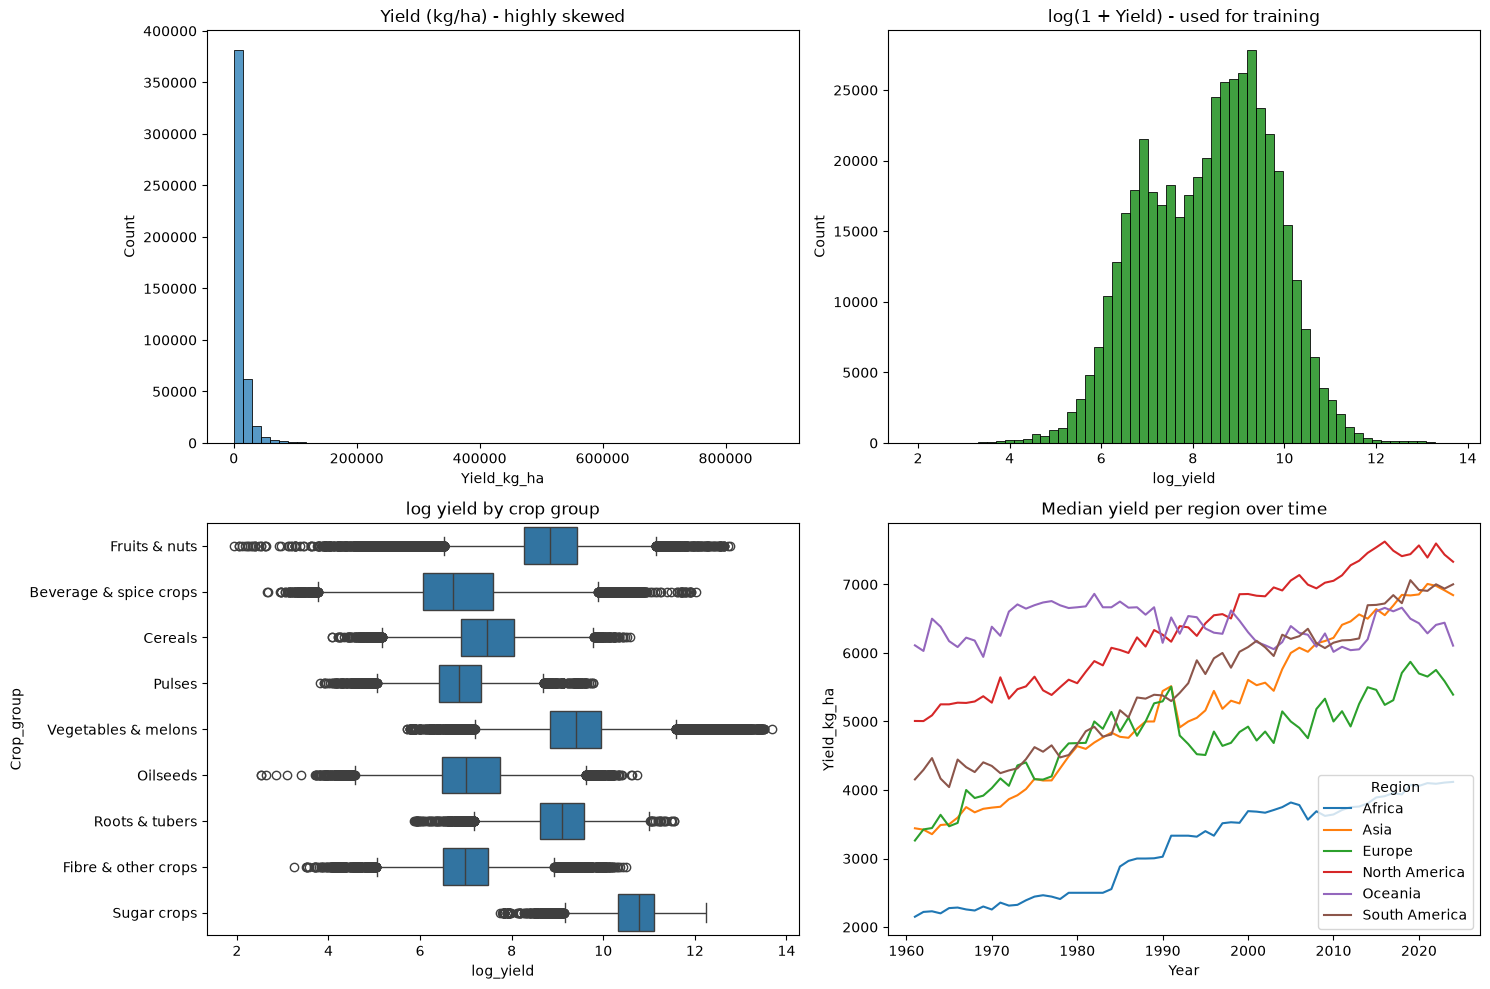

In [9]:
# ============================================================
# 9. EXPLORATORY DATA ANALYSIS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Yield distribution before and after log transform
sns.histplot(data["Yield_kg_ha"], bins=60, ax=axes[0, 0])
axes[0, 0].set_title("Yield (kg/ha) - highly skewed")

sns.histplot(data["log_yield"], bins=60, ax=axes[0, 1], color="green")
axes[0, 1].set_title("log(1 + Yield) - used for training")

# Yield by crop group
sns.boxplot(data=data, y="Crop_group", x="log_yield", ax=axes[1, 0])
axes[1, 0].set_title("log yield by crop group")

# Median yield trend by region
trend = data.groupby(["Year", "Region"])["Yield_kg_ha"].median().reset_index()
sns.lineplot(data=trend, x="Year", y="Yield_kg_ha", hue="Region", ax=axes[1, 1])
axes[1, 1].set_title("Median yield per region over time")

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# 10. CORRELATION OF YIELD WITH AREA HARVESTED (raw data)
# ============================================================

check = data.dropna(subset=["Area_harvested_ha", "Production_t"]).copy()
check["log_area"] = np.log1p(check["Area_harvested_ha"])
check["log_production"] = np.log1p(check["Production_t"])

print(check[["log_yield", "log_area", "log_production"]].corr().round(3))

# NOTE: Yield = Production / Area harvested, so same-year Production and
# Area must NOT be used as inputs. They would leak the answer.
# Only PAST values (previous years) are used as features below.

del check
gc.collect()

                log_yield  log_area  log_production
log_yield           1.000    -0.170           0.304
log_area           -0.170     1.000           0.887
log_production      0.304     0.887           1.000


413

In [11]:
# ============================================================
# 11. FEATURE ENGINEERING (history-based, no data leakage)
# ============================================================

data = data.sort_values(["Area", "Item", "Year"]).reset_index(drop=True)
data["log_area"] = np.log1p(data["Area_harvested_ha"])


def add_lag(frame, column, k, new_name):
    """Value of `column` for the same country + crop, k years earlier."""
    lag = frame[["Area", "Item", "Year", column]].copy()
    lag["Year"] = lag["Year"] + k
    lag = lag.rename(columns={column: new_name})
    return frame.merge(lag, on=["Area", "Item", "Year"], how="left")


# Past yields
data = add_lag(data, "log_yield", 1, "lag1")
data = add_lag(data, "log_yield", 2, "lag2")
data = add_lag(data, "log_yield", 3, "lag3")

# Past area harvested
data = add_lag(data, "log_area", 1, "area_lag1")
data = add_lag(data, "log_area", 2, "area_lag2")

# Only keep rows that have last year's yield
data = data.dropna(subset=["lag1"]).copy()

data["lag2"] = data["lag2"].fillna(data["lag1"])
data["lag3"] = data["lag3"].fillna(data["lag2"])

data["roll_mean3"] = data[["lag1", "lag2", "lag3"]].mean(axis=1)
data["roll_std3"] = data[["lag1", "lag2", "lag3"]].std(axis=1, ddof=0)
data["delta_lag1"] = data["lag1"] - data["lag2"]
data["yield_trend3"] = data["lag1"] - data["lag3"]
data["area_growth"] = (data["area_lag1"] - data["area_lag2"]).fillna(0)
data["year_index"] = data["Year"] - data["Year"].min()

# Long-run average yield of the series (before this year)
grp = data.groupby(["Area", "Item"])["log_yield"]
data["hist_mean"] = ((grp.cumsum() - data["log_yield"]) / grp.cumcount().replace(0, np.nan))
data["hist_mean"] = data["hist_mean"].fillna(data["lag1"])

# ---- Weather proxy -------------------------------------------------
# No weather columns exist in the FAOSTAT crop file. As a proxy we measure how
# the OTHER countries of the same region growing the same crop changed
# this year compared with their own last year (drought / good season).
# The row's own yield is excluded from this value.
if USE_REGIONAL_SHOCK:
    data["change"] = data["log_yield"] - data["lag1"]
    g = data.groupby(["Region", "Item", "Year"])["change"]
    s, n = g.transform("sum"), g.transform("count")
    data["regional_shock"] = np.where(n >= 3, (s - data["change"]) / (n - 1).clip(lower=1), 0.0)
    data = data.drop(columns="change")

data = data.drop(columns=["log_area", "area_lag2"])

print("Dataset shape after feature engineering:", data.shape)
print("Years:", data["Year"].min(), "-", data["Year"].max())
print("Countries:", data["Area"].nunique(), "| Crops:", data["Item"].nunique())

data.head()

Dataset shape after feature engineering: (463280, 21)
Years: 1962 - 2024
Countries: 209 | Crops: 157


,Area,Item,Year,Area_harvested_ha,Production_t,Yield_kg_ha,log_yield,Region,Crop_group,lag1,...,lag3,area_lag1,roll_mean3,roll_std3,delta_lag1,yield_trend3,area_growth,year_index,hist_mean,regional_shock
1,Afghanistan,"Almonds, in shell",1977,6000.0,9000.0,1500.0,7.313887,Asia,Fruits & nuts,7.415777,...,7.415777,8.682877,7.415777,0.000000,0.000000,0.000000,0.000000,15,7.415777,0.065907
2,Afghanistan,"Almonds, in shell",1978,6000.0,12000.0,2000.0,7.601402,Asia,Fruits & nuts,7.313887,...,7.415777,8.699681,7.381814,0.048031,-0.101890,-0.101890,0.016804,16,7.313887,-0.088351
3,Afghanistan,"Almonds, in shell",1979,6000.0,10500.0,1750.0,7.467942,Asia,Fruits & nuts,7.601402,...,7.415777,8.699681,7.443689,0.119025,0.287516,0.185625,0.000000,17,7.457645,-0.130214
4,Afghanistan,"Almonds, in shell",1980,5800.0,9900.0,1706.9,7.443020,Asia,Fruits & nuts,7.467942,...,7.313887,8.699681,7.461077,0.117478,-0.133460,0.154056,0.000000,18,7.461077,-0.012552
5,Afghanistan,"Almonds, in shell",1981,5800.0,8000.0,1379.3,7.230056,Asia,Fruits & nuts,7.443020,...,7.601402,8.665786,7.504121,0.069536,-0.024923,-0.158383,-0.033896,19,7.456563,-0.017066


In [12]:
# ============================================================
# 12. DEFINE TARGET AND FEATURES
# ============================================================

# Target: log(1 + yield).  Predictions are converted back with expm1 -> kg/ha
y = data["log_yield"]

numerical_features = [
    "lag1", "lag2", "lag3", "hist_mean", "roll_mean3", "roll_std3",
    "delta_lag1", "yield_trend3", "area_lag1", "area_growth", "year_index"
]

if USE_REGIONAL_SHOCK:
    numerical_features.append("regional_shock")

categorical_features = ["Region", "Crop_group"]

X = data[numerical_features + categorical_features].copy()

# Columns kept only for the error analysis later
info = data[["Area", "Item", "Region", "Crop_group", "Year", "Yield_kg_ha"]].copy()

print("Features shape:", X.shape)
print("Missing values per column:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Features shape: (463280, 14)
Missing values per column:
Series([], dtype: int64)


In [13]:
# ============================================================
# 13. TRAIN-TEST SPLIT
# ============================================================

if SPLIT_TYPE == "random":

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=RANDOM_STATE
    )

else:

    train_mask = data["Year"] <= 2015

    X_train, y_train = X[train_mask], y[train_mask]
    X_test, y_test = X[~train_mask], y[~train_mask]

info_test = info.loc[X_test.index].copy()

print("Split type:", SPLIT_TYPE)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Split type: random
Training rows: 370624
Testing rows: 92656


In [14]:
# ============================================================
# 14. HANDLE MISSING VALUES, ONE-HOT ENCODING AND SCALING
# ============================================================

# Median of the training data only
numerical_medians = X_train[numerical_features].median()

X_train[numerical_features] = X_train[numerical_features].fillna(numerical_medians)
X_test[numerical_features] = X_test[numerical_features].fillna(numerical_medians)

# One-hot encoding
X_train = pd.get_dummies(X_train, columns=categorical_features, drop_first=True, dtype=np.uint8)
X_test = pd.get_dummies(X_test, columns=categorical_features, drop_first=True, dtype=np.uint8)

# Same columns in train and test
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

feature_names = X_train.columns.tolist()

# Scaling (fit on training data only)
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=feature_names, index=X_train.index
).astype(np.float32)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=feature_names, index=X_test.index
).astype(np.float32)

print("Number of features:", len(feature_names))
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Number of features: 25
Training shape: (370624, 25)
Testing shape: (92656, 25)


In [15]:
# ============================================================
# 15. SAMPLES FOR GRID SEARCH AND FINAL FITTING
# ============================================================

tune_index = X_train_scaled.sample(
    n=min(TUNE_ROWS, len(X_train_scaled)), random_state=RANDOM_STATE
).index

fit_index = X_train_scaled.sample(
    n=min(FIT_ROWS or len(X_train_scaled), len(X_train_scaled)), random_state=RANDOM_STATE
).index

X_tune, y_tune = X_train_scaled.loc[tune_index], y_train.loc[tune_index]
X_fit, y_fit = X_train_scaled.loc[fit_index], y_train.loc[fit_index]

print("Rows used for GridSearch:", len(X_tune))
print("Rows used for final fitting:", len(X_fit))

Rows used for GridSearch: 30000
Rows used for final fitting: 120000


In [16]:
# ============================================================
# 16. MODEL EVALUATION FUNCTION  (MAE, MSE, RMSE, R2)
# ============================================================

def evaluate_model(model, X_data, y_log, model_name, show=True):

    # back to kg/ha
    predictions = np.expm1(model.predict(X_data)).clip(min=0)
    actual = np.expm1(y_log)

    mae = mean_absolute_error(actual, predictions)
    mse = mean_squared_error(actual, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predictions)

    # same R2 on the log scale (not dominated by high-yield crops)
    r2_log = r2_score(y_log, np.log1p(predictions))

    if show:
        print("\n======================================")
        print(model_name)
        print("======================================")
        print("MAE      :", round(mae, 2), "kg/ha")
        print("MSE      :", round(mse, 2))
        print("RMSE     :", round(rmse, 2), "kg/ha")
        print("R2 Score :", round(r2, 4))
        print("R2 (log) :", round(r2_log, 4))

    return {
        "Model": model_name, "MAE": mae, "MSE": mse,
        "RMSE": rmse, "R2": r2, "R2 (log)": r2_log
    }, predictions

In [17]:
# ============================================================
# 17. LINEAR / POLYNOMIAL REGRESSION WITH GRID SEARCH
# ============================================================

print("Starting Polynomial Regression Grid Search...")

pipeline = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("linear", LinearRegression())
])

param_grid = {"poly__degree": [1, 2]}      # degree 1 = plain Linear Regression

gs_poly = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gs_poly.fit(X_tune, y_tune)

print("\nBest Parameters:", gs_poly.best_params_)
print("Best CV R2:", gs_poly.best_score_)

poly_model = clone(gs_poly.best_estimator_)
poly_model.fit(X_fit, y_fit)

print("Polynomial Regression Training Completed!")

Starting Polynomial Regression Grid Search...
Fitting 5 folds for each of 2 candidates, totalling 10 fits

Best Parameters: {'poly__degree': 2}
Best CV R2: 0.978177553974214
Polynomial Regression Training Completed!


In [18]:
# ============================================================
# 18. RIDGE REGRESSION WITH GRID SEARCH
# ============================================================

print("Starting Ridge Grid Search...")

pipeline = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("ridge", Ridge())
])

param_grid = {
    "poly__degree": [1, 2],
    "ridge__alpha": [0.1, 1, 10, 100]
}

gs_ridge = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gs_ridge.fit(X_tune, y_tune)

print("\nBest Parameters:", gs_ridge.best_params_)
print("Best CV R2:", gs_ridge.best_score_)

ridge_model = clone(gs_ridge.best_estimator_)
ridge_model.fit(X_fit, y_fit)

print("Ridge Training Completed!")

Starting Ridge Grid Search...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best Parameters: {'poly__degree': 2, 'ridge__alpha': 100}
Best CV R2: 0.9781889292277448
Ridge Training Completed!


In [19]:
# ============================================================
# 19. LASSO REGRESSION WITH GRID SEARCH
# ============================================================

print("Starting Lasso Grid Search...")

pipeline = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("lasso", Lasso(max_iter=5000, tol=1e-3))
])

param_grid = {
    "poly__degree": [1, 2],
    "lasso__alpha": [0.0005, 0.005, 0.05]
}

gs_lasso = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gs_lasso.fit(X_tune, y_tune)

print("\nBest Parameters:", gs_lasso.best_params_)
print("Best CV R2:", gs_lasso.best_score_)

lasso_model = clone(gs_lasso.best_estimator_)
lasso_model.fit(X_fit, y_fit)

print("Lasso Training Completed!")

Starting Lasso Grid Search...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best Parameters: {'lasso__alpha': 0.0005, 'poly__degree': 2}
Best CV R2: 0.9782903338912898
Lasso Training Completed!


In [20]:
# ============================================================
# 20. RANDOM FOREST WITH GRID SEARCH
# ============================================================

print("Starting Random Forest Grid Search...")

rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)

param_grid = {
    "n_estimators": [100],
    "max_depth": [10, 16],
    "min_samples_leaf": [5, 10],
    "max_features": [0.5]
}

gs_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=1,
    verbose=1
)

gs_rf.fit(X_tune, y_tune)

print("\nBest Parameters:", gs_rf.best_params_)
print("Best CV R2:", gs_rf.best_score_)

rf_model = clone(gs_rf.best_estimator_)
rf_model.fit(X_fit, y_fit)

print("Random Forest Training Completed!")

Starting Random Forest Grid Search...
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Best Parameters: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 10, 'n_estimators': 100}
Best CV R2: 0.9776461686106638
Random Forest Training Completed!


In [21]:
# ============================================================
# 21. EVALUATE ALL MODELS ON THE TEST SET
# ============================================================

models = {
    "Polynomial Regression": (poly_model, gs_poly),
    "Ridge Regression": (ridge_model, gs_ridge),
    "Lasso Regression": (lasso_model, gs_lasso),
    "Random Forest": (rf_model, gs_rf)
}

results = []
test_predictions = {}

for name, (model, gs) in models.items():

    res, pred = evaluate_model(model, X_test_scaled, y_test, name)

    res["CV R2"] = gs.best_score_
    res["Train R2"] = r2_score(np.expm1(y_fit), np.expm1(model.predict(X_fit)).clip(min=0))

    results.append(res)
    test_predictions[name] = pred

# Baseline: "same yield as last year"
baseline_pred = np.expm1(X_test["lag1"].values)

res, _ = evaluate_model(
    type("Last", (), {"predict": lambda self, X: X["lag1"].values})(),
    X_test, y_test, "Baseline (last year's yield)"
)

res["CV R2"] = np.nan
res["Train R2"] = np.nan
results.append(res)


Polynomial Regression
MAE      : 978.23 kg/ha
MSE      : 13013403.97
RMSE     : 3607.41 kg/ha
R2 Score : 0.9692
R2 (log) : 0.9782

Ridge Regression
MAE      : 979.47 kg/ha
MSE      : 13029296.27
RMSE     : 3609.61 kg/ha
R2 Score : 0.9692
R2 (log) : 0.9782

Lasso Regression
MAE      : 967.36 kg/ha
MSE      : 12760644.68
RMSE     : 3572.2 kg/ha
R2 Score : 0.9698
R2 (log) : 0.9782

Random Forest
MAE      : 987.28 kg/ha
MSE      : 14486449.55
RMSE     : 3806.11 kg/ha
R2 Score : 0.9657
R2 (log) : 0.9779

Baseline (last year's yield)
MAE      : 971.81 kg/ha
MSE      : 12828311.67
RMSE     : 3581.66 kg/ha
R2 Score : 0.9696
R2 (log) : 0.9744


In [22]:
# ============================================================
# 22. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

print("\n======================================")
print("MODEL COMPARISON")
print("======================================")

print(
    results_df[["Model", "CV R2", "Train R2", "MAE", "MSE", "RMSE", "R2", "R2 (log)"]]
    .sort_values(by="R2", ascending=False)
    .round(4)
    .to_string(index=False)
)


MODEL COMPARISON
                       Model  CV R2  Train R2      MAE          MSE      RMSE     R2  R2 (log)
            Lasso Regression 0.9783    0.9718 967.3623 1.276064e+07 3572.2045 0.9698    0.9782
Baseline (last year's yield)    NaN       NaN 971.8116 1.282831e+07 3581.6633 0.9696    0.9744
       Polynomial Regression 0.9782    0.9715 978.2295 1.301340e+07 3607.4096 0.9692    0.9782
            Ridge Regression 0.9782    0.9714 979.4736 1.302930e+07 3609.6117 0.9692    0.9782
               Random Forest 0.9776    0.9759 987.2808 1.448645e+07 3806.1069 0.9657    0.9779


In [23]:
# ============================================================
# 23. SELECT BEST MODEL (using cross-validation R2, not the test set)
# ============================================================

cv_table = results_df.dropna(subset=["CV R2"])

best_model_name = cv_table.loc[cv_table["CV R2"].idxmax(), "Model"]

best_model = models[best_model_name][0]
best_params = models[best_model_name][1].best_params_

print("Best Model:", best_model_name)
print("Best Parameters:", best_params)

Best Model: Lasso Regression
Best Parameters: {'lasso__alpha': 0.0005, 'poly__degree': 2}


In [24]:
# ============================================================
# 24. SMOTE FOR REGRESSION
# ============================================================

# SMOTE needs classes, so it cannot be used directly on a continuous target.
# Here rare yield ranges (lowest 5% and highest 5% of log-yield) are treated as
# the "minority classes". New rows are created by interpolating between a rare row
# and one of its k nearest rare neighbours (numeric features + target are
# interpolated, Region / Crop_group dummies are copied from the base row).

def smote_regression(X_data, y_data, numeric_cols, tail=0.05, ratio=1.0, k=5, seed=RANDOM_STATE):

    rng = np.random.RandomState(seed)

    X_data = X_data.reset_index(drop=True)
    y_data = pd.Series(np.asarray(y_data)).reset_index(drop=True)

    low, high = np.quantile(y_data, [tail, 1 - tail])

    X_parts, y_parts = [X_data], [y_data]

    for mask in (y_data <= low, y_data >= high):

        idx = np.where(mask)[0]
        n_new = int(len(idx) * ratio)

        if len(idx) <= k or n_new == 0:
            continue

        nn = NearestNeighbors(n_neighbors=k + 1).fit(X_data.loc[idx, numeric_cols])
        neighbours = nn.kneighbors(X_data.loc[idx, numeric_cols], return_distance=False)[:, 1:]

        base = rng.randint(0, len(idx), n_new)
        other = neighbours[base, rng.randint(0, k, n_new)]
        gap = rng.rand(n_new, 1)

        base_rows = X_data.loc[idx[base]].reset_index(drop=True)
        other_rows = X_data.loc[idx[other]].reset_index(drop=True)

        new_rows = base_rows.copy()
        new_rows[numeric_cols] = (
            base_rows[numeric_cols].values
            + gap * (other_rows[numeric_cols].values - base_rows[numeric_cols].values)
        )

        y_base = y_data.loc[idx[base]].values
        y_other = y_data.loc[idx[other]].values

        X_parts.append(new_rows)
        y_parts.append(pd.Series(y_base + gap[:, 0] * (y_other - y_base)))

    return (
        pd.concat(X_parts, ignore_index=True),
        pd.concat(y_parts, ignore_index=True)
    )


# Scaled version of the numeric columns (they have the same names)
Xa, Xv, ya, yv = train_test_split(X_fit, y_fit, test_size=0.20, random_state=RANDOM_STATE)

Xa_smote, ya_smote = smote_regression(Xa, ya, numerical_features)

print("Rows before SMOTE:", len(Xa), "| after SMOTE:", len(Xa_smote))

# Validation (taken from TRAINING data only): without SMOTE vs with SMOTE
plain_model = clone(best_model).fit(Xa, ya)
smote_model = clone(best_model).fit(Xa_smote, ya_smote)

r2_plain = r2_score(np.expm1(yv), np.expm1(plain_model.predict(Xv)).clip(min=0))
r2_smote = r2_score(np.expm1(yv), np.expm1(smote_model.predict(Xv)).clip(min=0))

print("\nValidation R2 without SMOTE:", round(r2_plain, 4))
print("Validation R2 with SMOTE   :", round(r2_smote, 4))

if r2_smote > r2_plain:

    print("\nSMOTE improved validation R2 -> refitting best model with SMOTE data")

    X_fit_smote, y_fit_smote = smote_regression(X_fit, y_fit, numerical_features)

    final_model = clone(best_model).fit(X_fit_smote, y_fit_smote)
    final_model_name = best_model_name + " + SMOTE"

else:

    print("\nSMOTE did not help -> using the model without SMOTE")

    final_model = best_model
    final_model_name = best_model_name

res, final_pred = evaluate_model(final_model, X_test_scaled, y_test, "FINAL MODEL: " + final_model_name)

Rows before SMOTE: 96000 | after SMOTE: 105625

Validation R2 without SMOTE: 0.9759
Validation R2 with SMOTE   : 0.977

SMOTE improved validation R2 -> refitting best model with SMOTE data

FINAL MODEL: Lasso Regression + SMOTE
MAE      : 961.3 kg/ha
MSE      : 12275068.04
RMSE     : 3503.58 kg/ha
R2 Score : 0.9709
R2 (log) : 0.9781


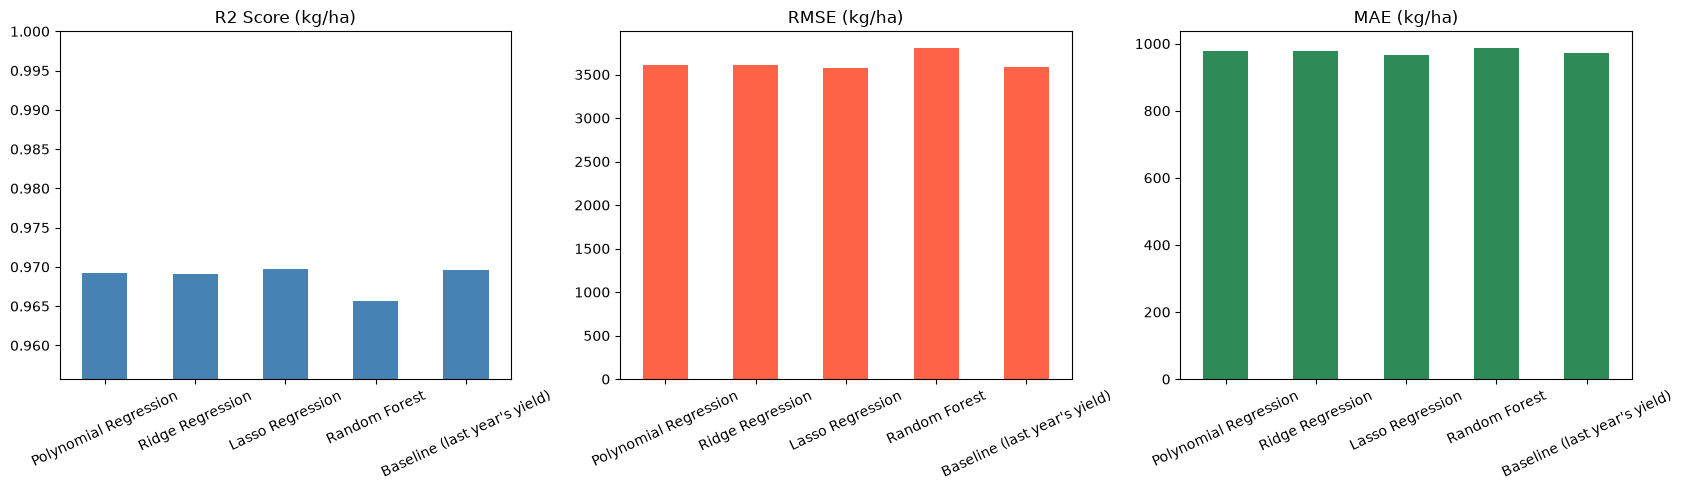

In [25]:
# ============================================================
# 25. MODEL COMPARISON GRAPH
# ============================================================

plot_df = results_df.set_index("Model")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

plot_df["R2"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("R2 Score (kg/ha)")
axes[0].set_ylim(plot_df["R2"].min() - 0.01, 1)

plot_df["RMSE"].plot(kind="bar", ax=axes[1], color="tomato")
axes[1].set_title("RMSE (kg/ha)")

plot_df["MAE"].plot(kind="bar", ax=axes[2], color="seagreen")
axes[2].set_title("MAE (kg/ha)")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

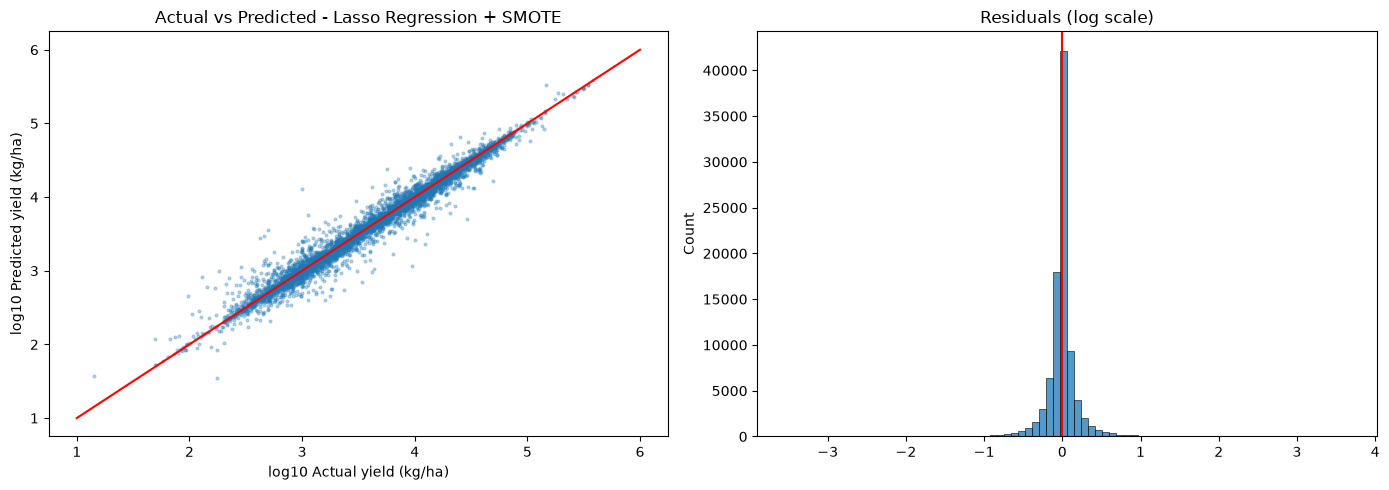

In [26]:
# ============================================================
# 26. ACTUAL VS PREDICTED AND RESIDUALS
# ============================================================

actual = np.expm1(y_test.values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample = np.random.RandomState(1).choice(len(actual), size=min(8000, len(actual)), replace=False)

axes[0].scatter(np.log10(actual[sample] + 1), np.log10(final_pred[sample] + 1), s=4, alpha=0.3)
axes[0].plot([1, 6], [1, 6], color="red")
axes[0].set_xlabel("log10 Actual yield (kg/ha)")
axes[0].set_ylabel("log10 Predicted yield (kg/ha)")
axes[0].set_title("Actual vs Predicted - " + final_model_name)

log_error = np.log1p(final_pred) - np.log1p(actual)

sns.histplot(log_error, bins=80, ax=axes[1])
axes[1].axvline(0, color="red")
axes[1].set_title("Residuals (log scale)")

plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# 27. ERROR ANALYSIS TABLE
# ============================================================

error_df = info_test.copy()

error_df["actual"] = actual
error_df["predicted"] = final_pred
error_df["error"] = error_df["predicted"] - error_df["actual"]
error_df["abs_error"] = error_df["error"].abs()
error_df["pct_error"] = error_df["abs_error"] / error_df["actual"] * 100
error_df["log_error"] = log_error

# log(actual) - log(predicted): used by the API to give an error range
error_df["log_gap"] = -log_error


def group_errors(frame, column, min_rows=30):

    rows = []

    for name, g in frame.groupby(column):

        if len(g) < min_rows:
            continue

        rows.append({
            column: name,
            "Rows": len(g),
            "MAE": g["abs_error"].mean(),
            "RMSE": np.sqrt((g["error"] ** 2).mean()),
            "R2": r2_score(g["actual"], g["predicted"]),
            "Median % Error": g["pct_error"].median(),
            "Uncertainty (std of log error)": g["log_error"].std()
        })

    return pd.DataFrame(rows).sort_values("Uncertainty (std of log error)", ascending=False)


by_group = group_errors(error_df, "Crop_group")
by_region = group_errors(error_df, "Region")
by_crop = group_errors(error_df, "Item", min_rows=150)
by_country = group_errors(error_df, "Area", min_rows=150)

print("ERROR BY CROP GROUP (most uncertain first)")
print(by_group.round(3).to_string(index=False))

print("\nERROR BY REGION (most uncertain first)")
print(by_region.round(3).to_string(index=False))

ERROR BY CROP GROUP (most uncertain first)
            Crop_group  Rows      MAE     RMSE    R2  Median % Error  Uncertainty (std of log error)
                Pulses  6626  171.711  390.565 0.888           6.366                           0.241
              Oilseeds  8697  214.514  495.265 0.977           5.905                           0.218
               Cereals 10679  273.714  594.902 0.926           7.215                           0.217
         Fruits & nuts 24479 1071.880 2944.532 0.931           4.686                           0.216
   Fibre & other crops  4718  162.775  458.813 0.948           5.142                           0.206
Beverage & spice crops  5609  269.690 1284.232 0.963           4.099                           0.205
   Vegetables & melons 23516 1748.386 5861.338 0.970           4.197                           0.183
        Roots & tubers  6422  911.114 1921.199 0.946           3.393                           0.166
           Sugar crops  1910 4009.792 6322.460 0

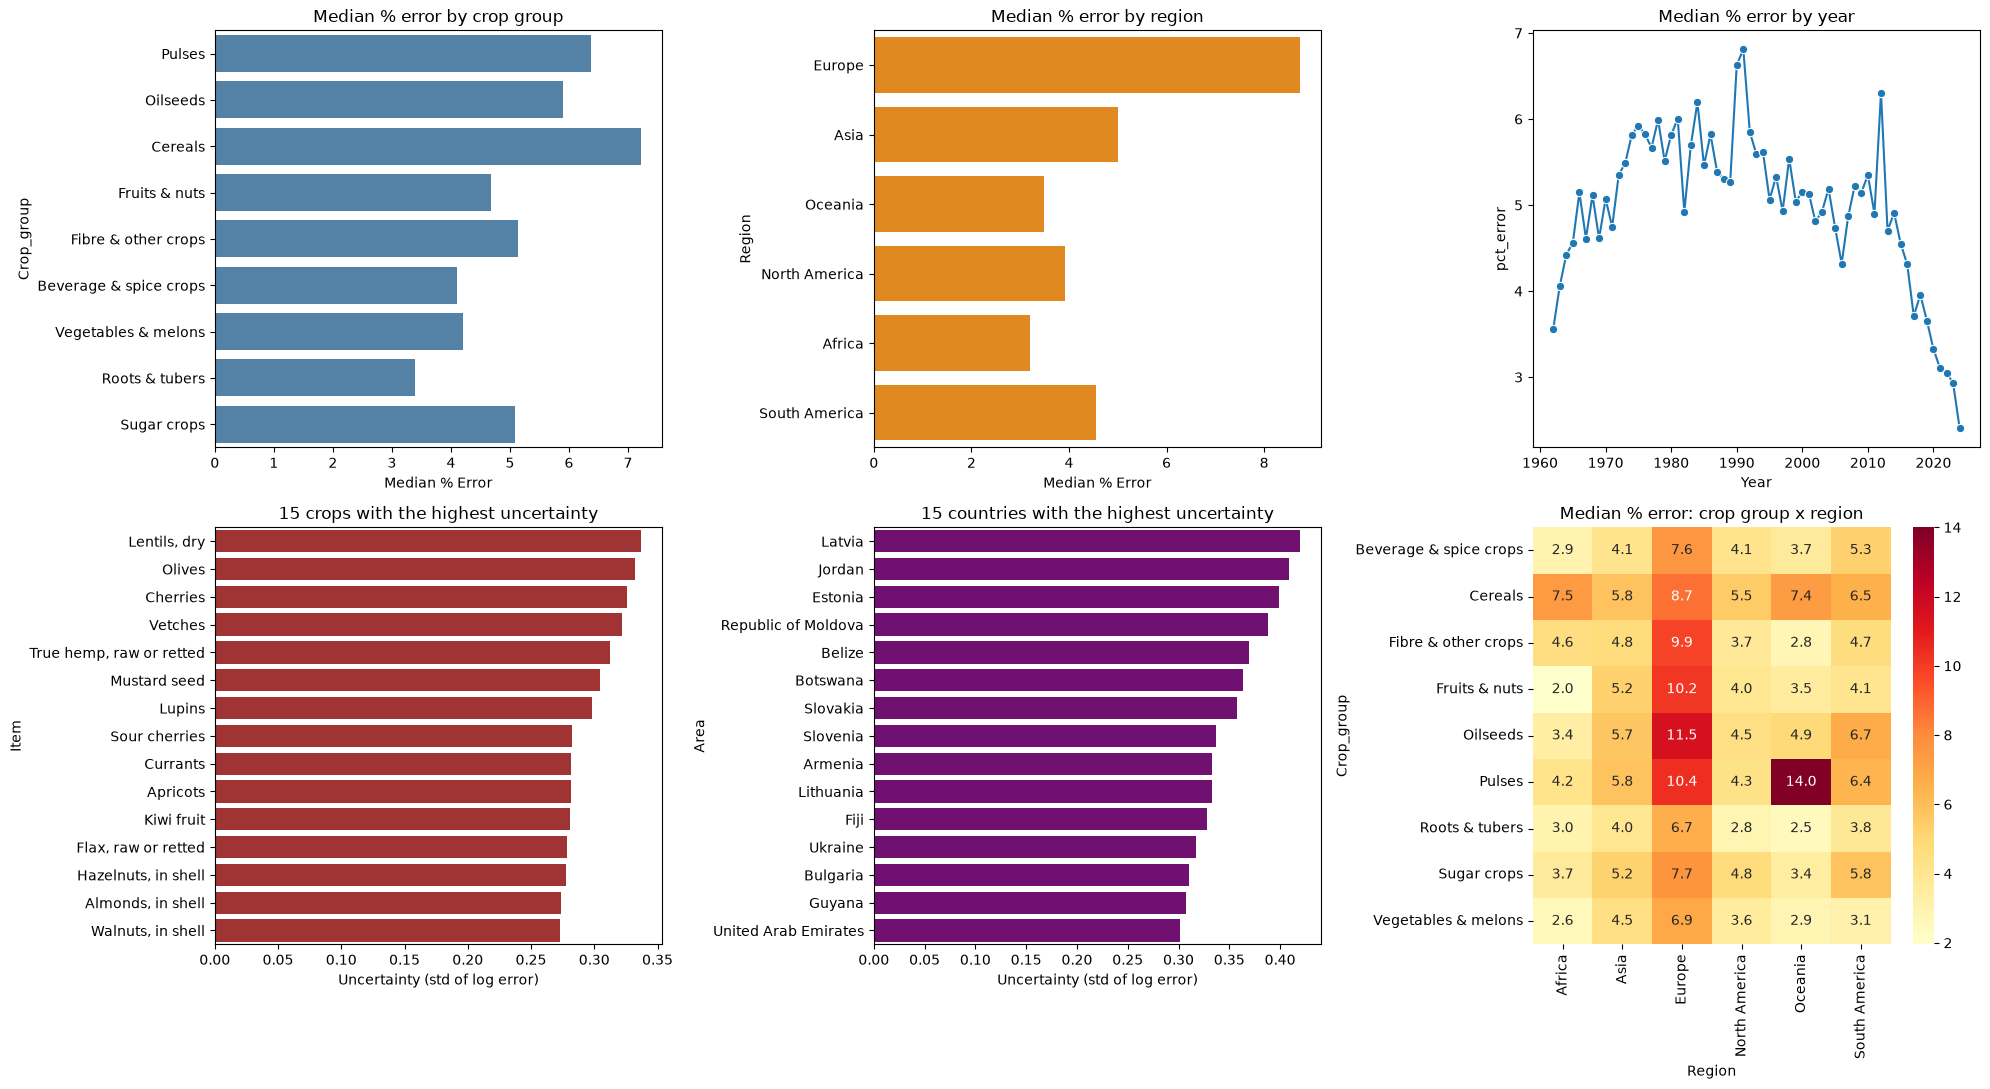

In [28]:
# ============================================================
# 28. ERROR ANALYSIS DASHBOARD
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. Crop group
sns.barplot(data=by_group, y="Crop_group", x="Median % Error", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Median % error by crop group")

# 2. Region
sns.barplot(data=by_region, y="Region", x="Median % Error", ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Median % error by region")

# 3. Error over the years
by_year = error_df.groupby("Year")["pct_error"].median().reset_index()
sns.lineplot(data=by_year, x="Year", y="pct_error", ax=axes[0, 2], marker="o")
axes[0, 2].set_title("Median % error by year")

# 4. Most uncertain crops
top_crops = by_crop.head(15)
sns.barplot(data=top_crops, y="Item", x="Uncertainty (std of log error)", ax=axes[1, 0], color="firebrick")
axes[1, 0].set_title("15 crops with the highest uncertainty")

# 5. Most uncertain countries
top_countries = by_country.head(15)
sns.barplot(data=top_countries, y="Area", x="Uncertainty (std of log error)", ax=axes[1, 1], color="purple")
axes[1, 1].set_title("15 countries with the highest uncertainty")

# 6. Crop group x region heatmap
heat = error_df.pivot_table(index="Crop_group", columns="Region", values="pct_error", aggfunc="median")
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1, 2])
axes[1, 2].set_title("Median % error: crop group x region")

plt.tight_layout()
plt.show()

Top 15 Important Features:
                  Feature  Importance
                     lag1    1.862409
               delta_lag1    0.003182
             yield_trend3    0.001258
                hist_mean    0.000461
               roll_mean3    0.000438
           regional_shock    0.000407
                roll_std3    0.000368
            Region_Europe    0.000159
              Region_Asia    0.000119
Crop_group_Roots & tubers    0.000081
                     lag3    0.000079
        Crop_group_Pulses    0.000078
                area_lag1    0.000078
              area_growth    0.000036
      Crop_group_Oilseeds    0.000035


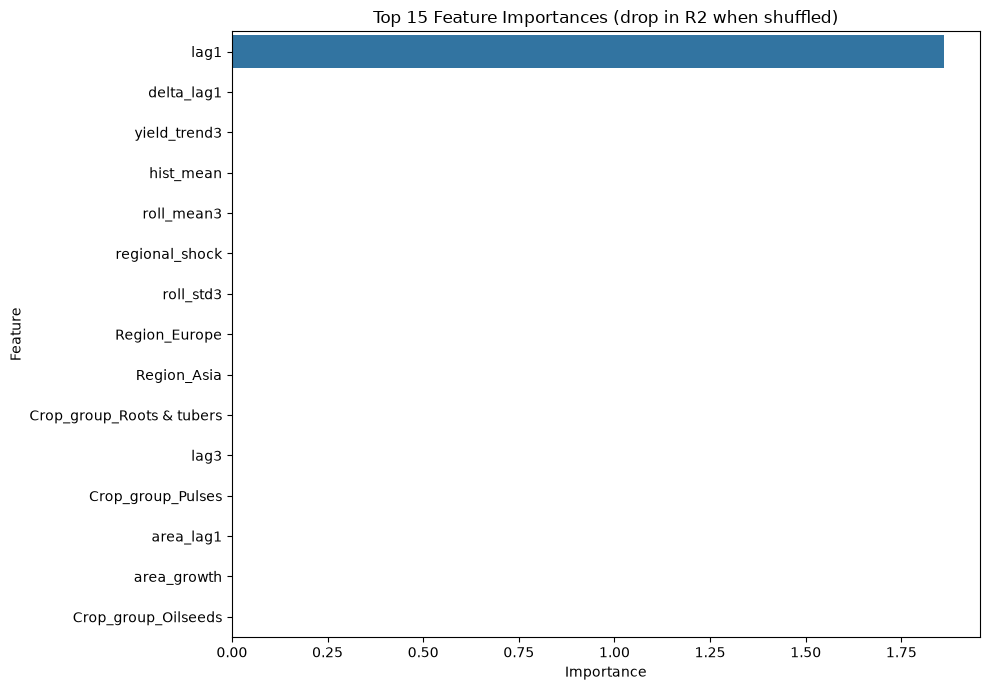

In [29]:
# ============================================================
# 29. FEATURE IMPORTANCE (permutation importance, works for any model)
# ============================================================

imp_index = X_test_scaled.sample(n=min(5000, len(X_test_scaled)), random_state=RANDOM_STATE).index

perm = permutation_importance(
    final_model,
    X_test_scaled.loc[imp_index],
    y_test.loc[imp_index],
    scoring="r2",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm.importances_mean
}).sort_values(by="Importance", ascending=False)

print("Top 15 Important Features:")
print(feature_importance.head(15).to_string(index=False))

plt.figure(figsize=(10, 7))

sns.barplot(data=feature_importance.head(15), x="Importance", y="Feature")

plt.title("Top 15 Feature Importances (drop in R2 when shuffled)")

plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# 30. ACCURACY WITH MINIMUM INPUT (what the API uses)
# ============================================================

# The API asks only for region, crop group, year and LAST YEAR'S yield.
# Everything else is filled with neutral values, exactly as main.py does.

X_min = X_test.copy()

for col in ["lag2", "lag3", "hist_mean", "roll_mean3"]:
    X_min[col] = X_min["lag1"]

for col in ["roll_std3", "delta_lag1", "yield_trend3", "area_growth", "regional_shock"]:
    if col in X_min.columns:
        X_min[col] = 0.0

X_min["area_lag1"] = numerical_medians["area_lag1"]

X_min_scaled = pd.DataFrame(
    scaler.transform(X_min), columns=feature_names, index=X_min.index
)

res_min, pred_min = evaluate_model(
    final_model, X_min_scaled, y_test, "MINIMUM INPUT (API)"
)

# Error range seen with minimum input: log(actual) - log(predicted)
error_min = info_test.copy()
error_min["log_gap"] = np.log1p(actual) - np.log1p(pred_min)


MINIMUM INPUT (API)
MAE      : 977.93 kg/ha
MSE      : 12755580.42
RMSE     : 3571.5 kg/ha
R2 Score : 0.9698
R2 (log) : 0.9745


In [31]:
# ============================================================
# 31. SAVE BEST MODEL
# ============================================================

# Typical error range (10th and 90th percentile of log(actual) - log(predicted))
def gap_range(frame, column):
    q = frame.groupby(column)["log_gap"].quantile([0.10, 0.90]).unstack()
    q.columns = ["low", "high"]
    return q.to_dict("index")

overall_range = {
    "low": float(error_min["log_gap"].quantile(0.10)),
    "high": float(error_min["log_gap"].quantile(0.90))
}

model_package = {
    "model": final_model,
    "scaler": scaler,
    "feature_names": feature_names,
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "numerical_medians": numerical_medians,
    "best_model_name": final_model_name,
    "best_params": best_params,

    "first_year": int(data["Year"].min()),
    "last_year": int(data["Year"].max()),
    "split_type": SPLIT_TYPE,
    "test_metrics": {k: float(v) for k, v in res_min.items() if k != "Model"},
    "test_metrics_full_input": {k: float(v) for k, v in res.items() if k != "Model"},

    "error_range_by_crop_group": gap_range(error_min, "Crop_group"),
    "error_range_by_region": gap_range(error_min, "Region"),
    "error_range_overall": overall_range,

    "target_definition": "log1p(Yield in kg/ha). Use np.expm1(model.predict(X)) to get kg/ha"
}

joblib.dump(
    model_package,
    "best_yield_model.pkl",
    compress=3
)

print("\n======================================")
print("MODEL SAVED SUCCESSFULLY!")
print("File: best_yield_model.pkl")
print("======================================")

print("\nProject Execution Completed!")


MODEL SAVED SUCCESSFULLY!
File: best_yield_model.pkl

Project Execution Completed!
